Sample rate: 44100 Hz
Duration: 132.92 seconds


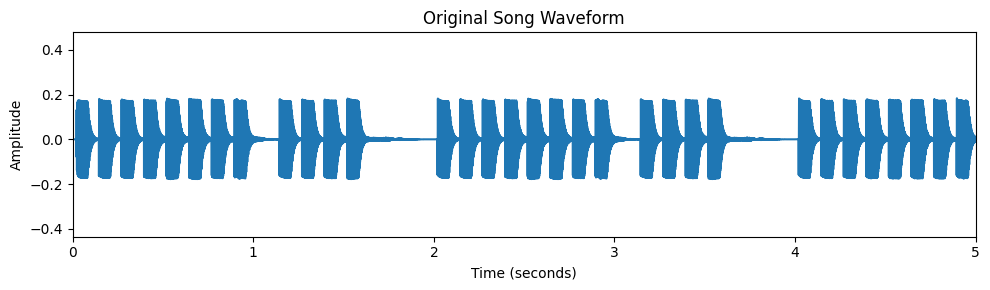

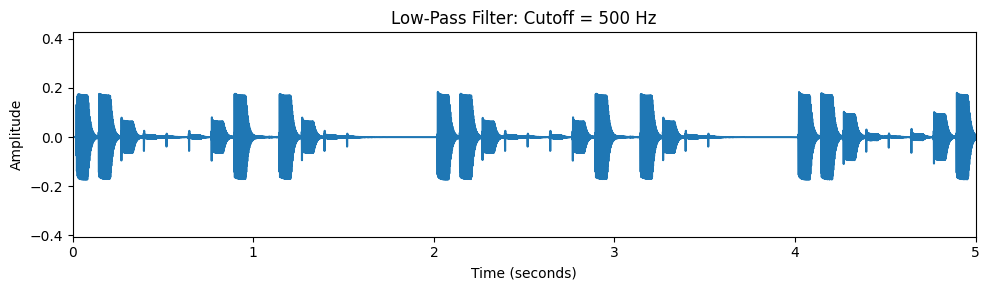

Saved: Lowpass_500Hz.wav


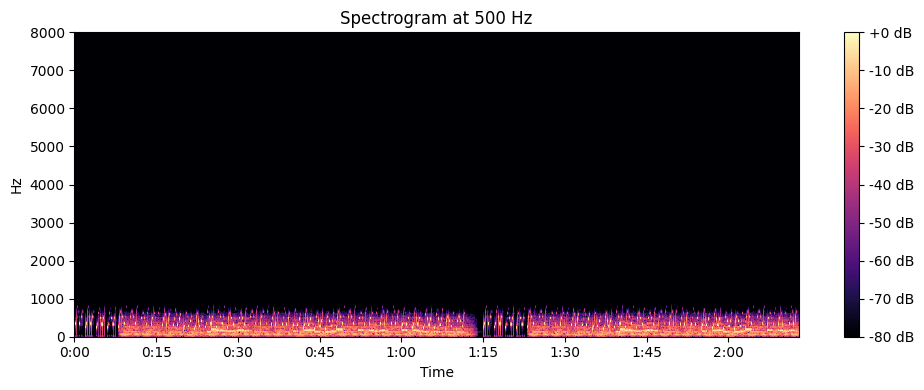

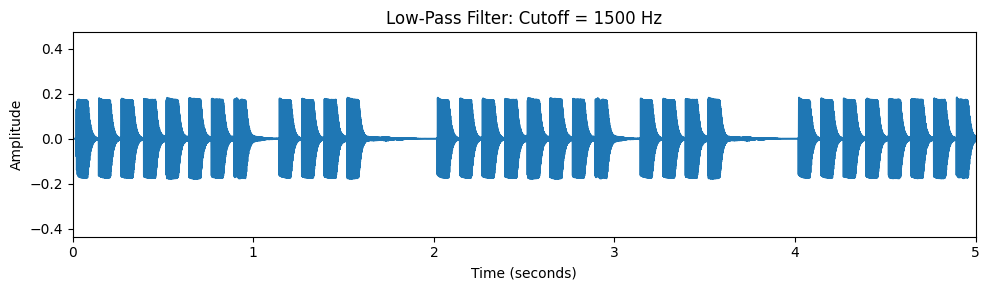

Saved: Lowpass_1500Hz.wav


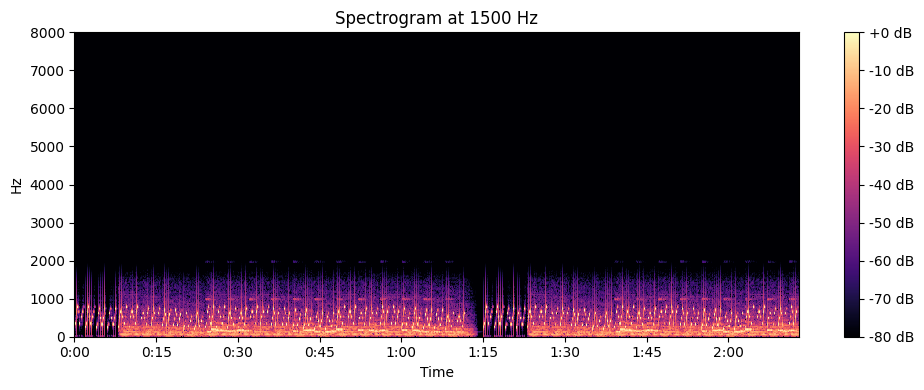

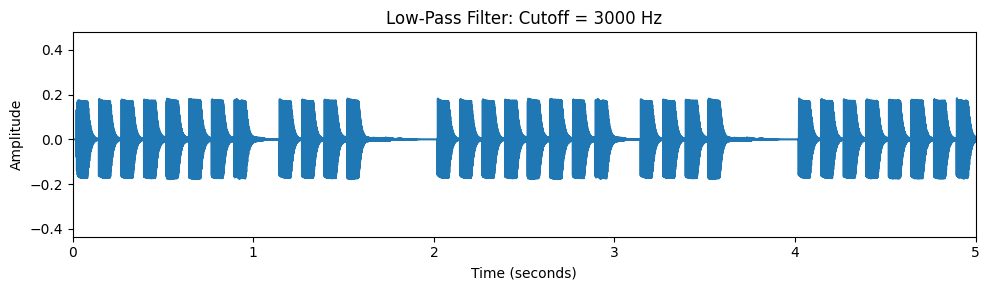

Saved: Lowpass_3000Hz.wav


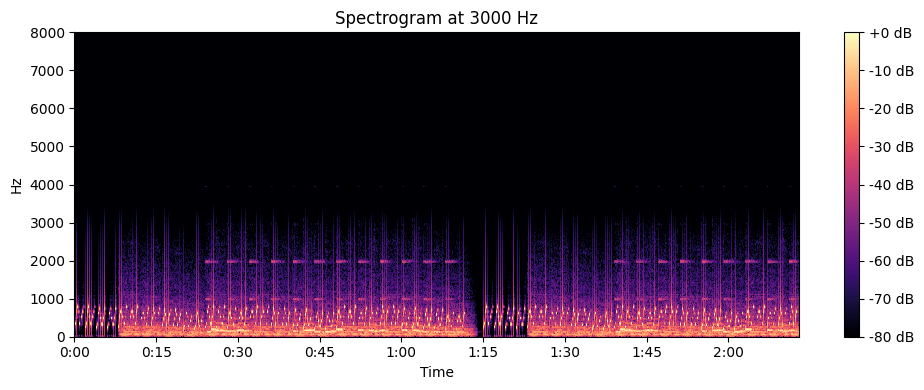

In [1]:
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf
from scipy.signal import butter, sosfiltfilt

# 1. Load the original song
filename = "OPE4.mp3"

audio, sr = librosa.load(filename, sr=None, mono=True)

print("Sample rate:", sr, "Hz")
print("Duration:", round(len(audio) / sr, 2), "seconds")

# 2. Create a low-pass filter
def low_pass_filter(data, cutoff, sr):
    filter_coeff = butter(
        6, cutoff, btype="lowpass",
        fs=sr, output="sos"
    )
    return sosfiltfilt(filter_coeff, data)

# 3. Try three different cutoff frequencies
cutoff_frequencies = [500, 1500, 3000]

# Display the original waveform
time = np.arange(len(audio)) / sr
plt.figure(figsize=(10, 3))
plt.plot(time, audio)
plt.xlim(0, min(5, len(audio) / sr))
plt.title("Original Song Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.tight_layout()
plt.show()

# 4. Filter, save, and plot each result
for cutoff in cutoff_frequencies:
    filtered_audio = low_pass_filter(audio, cutoff, sr)

    # Save the filtered audio as a WAV file
    filename_out = f"Lowpass_{cutoff}Hz.wav"
    sf.write(filename_out, filtered_audio, sr)

    # Plot the filtered waveform
    plt.figure(figsize=(10, 3))
    plt.plot(time, filtered_audio)
    plt.xlim(0, min(5, len(audio) / sr))
    plt.title(f"Low-Pass Filter: Cutoff = {cutoff} Hz")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Amplitude")
    plt.tight_layout()
    plt.show()

    print("Saved:", filename_out)

    # Plot the filtered spectrogram
    D = librosa.amplitude_to_db(
        np.abs(librosa.stft(filtered_audio)),
        ref=np.max
    )

    plt.figure(figsize=(10, 4))
    librosa.display.specshow(
        D, sr=sr, x_axis="time", y_axis="hz"
    )
    plt.ylim(0, min(8000, sr / 2))
    plt.colorbar(format="%+2.0f dB")
    plt.title(f"Spectrogram at {cutoff} Hz")
    plt.tight_layout()
    plt.show()


Sample rate: 44100 Hz
Duration: 132.92 seconds


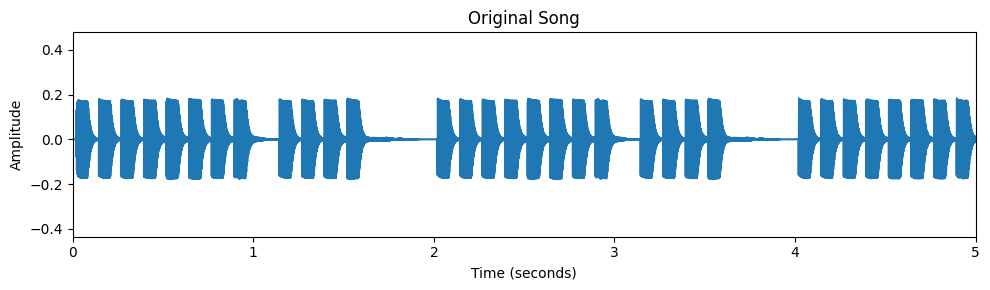

Saved: Lowpass_500Hz.mp3


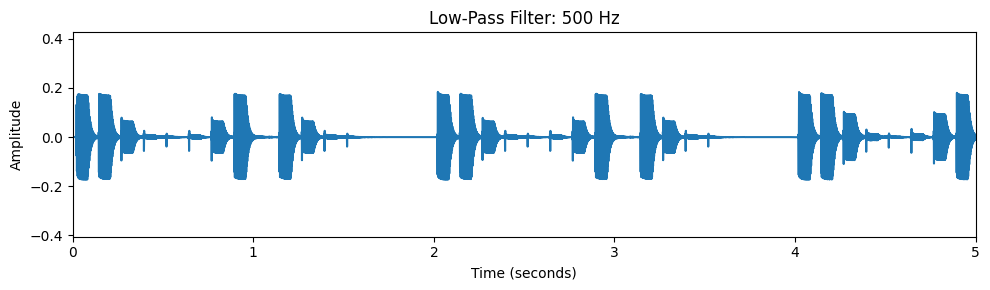

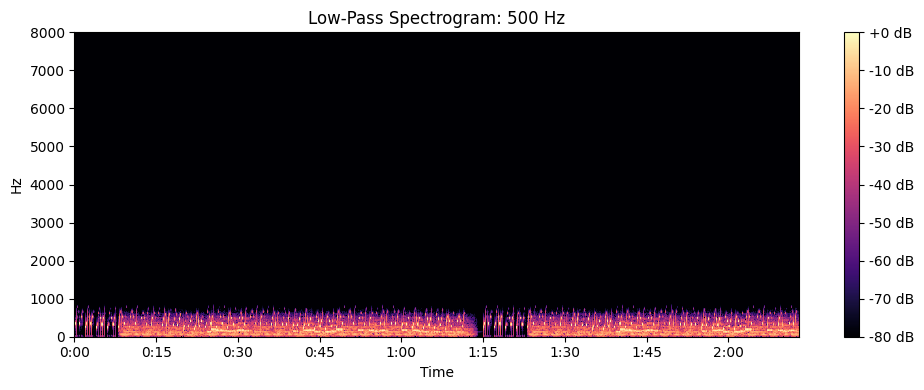

Saved: Lowpass_1500Hz.mp3


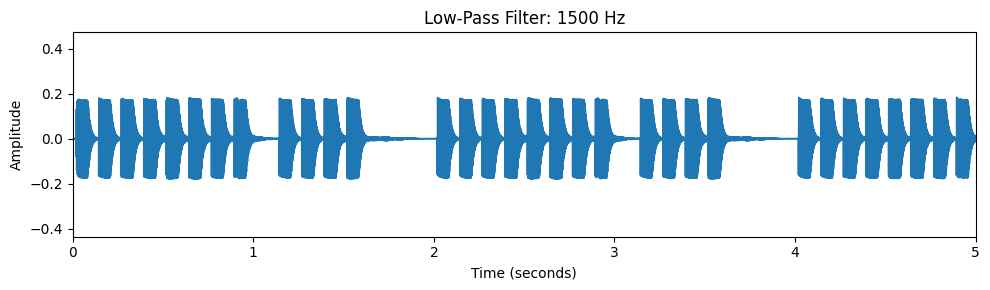

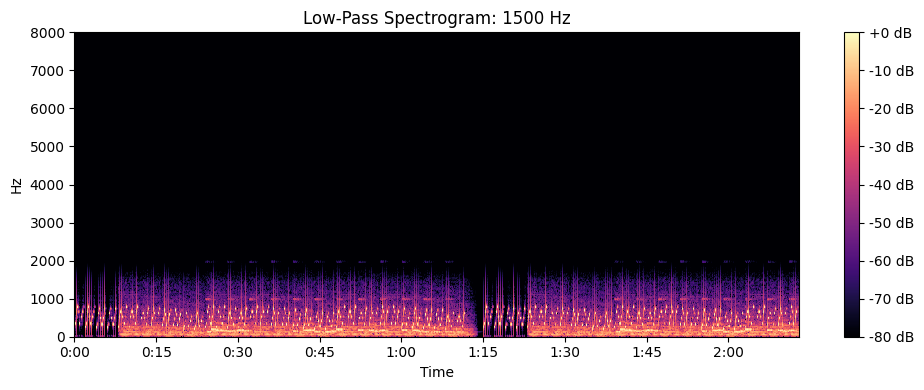

Saved: Lowpass_3000Hz.mp3


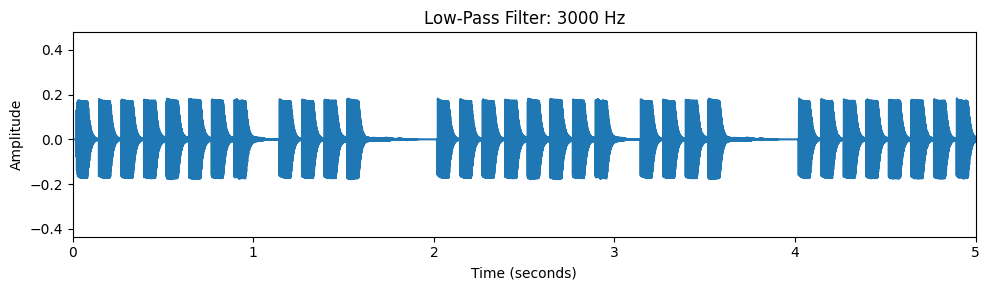

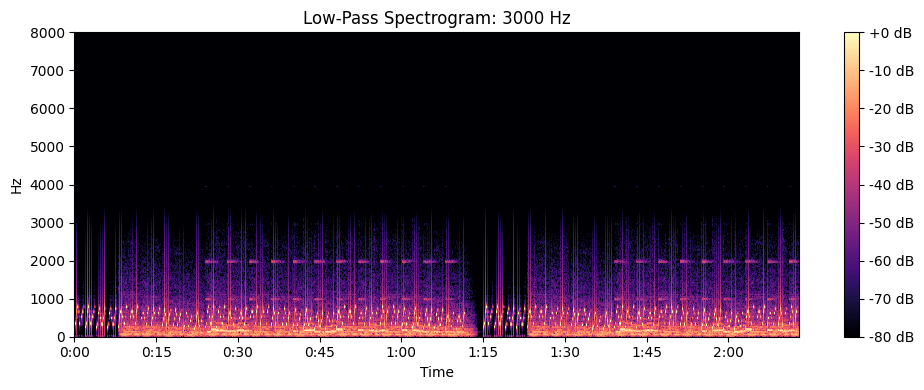

Saved: Filtered_Vocals.mp3
Saved: Estimated_Background.mp3


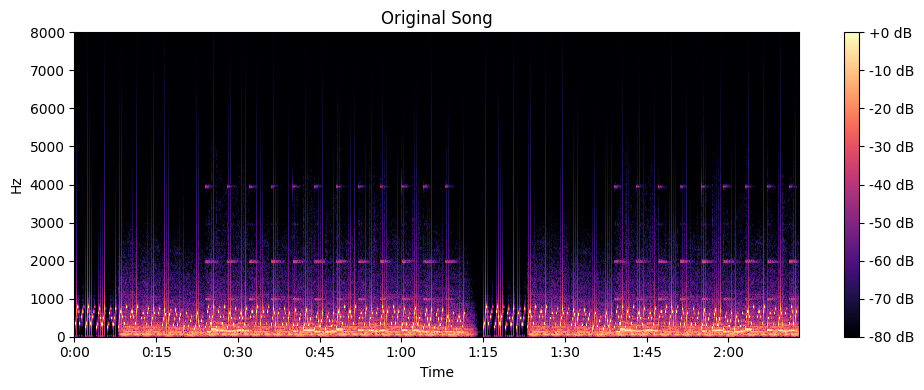

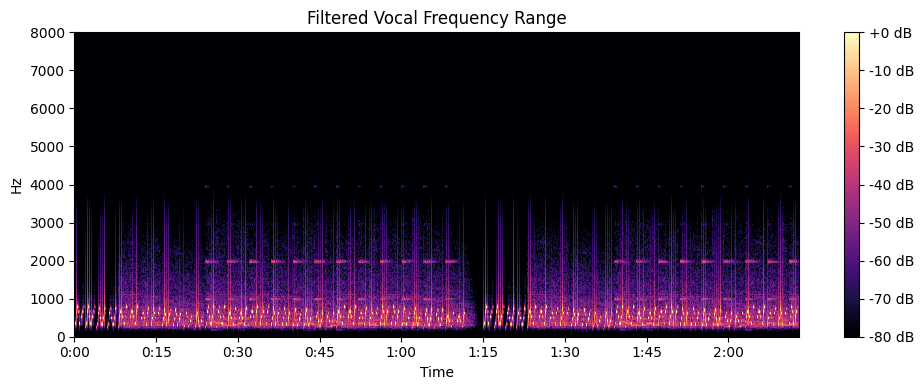

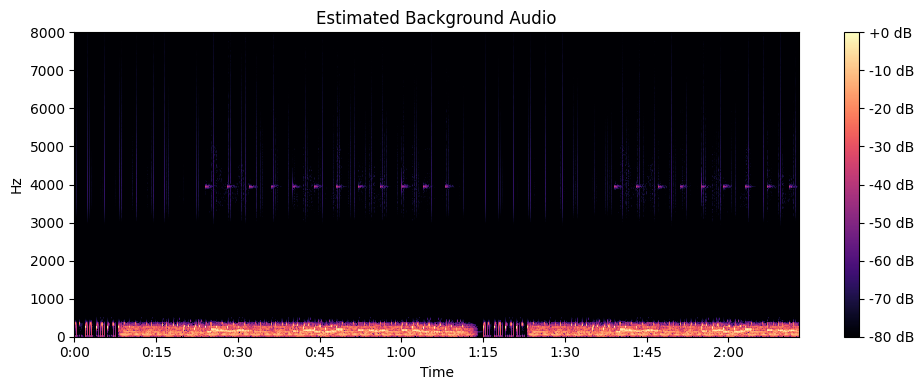

In [3]:

import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf
import subprocess
import imageio_ffmpeg
from scipy.signal import butter, sosfiltfilt

# Load the song
filename = "OPE4.mp3"
audio, sr = librosa.load(filename, sr=None, mono=True)

print("Sample rate:", sr, "Hz")
print("Duration:", round(len(audio) / sr, 2), "seconds")

# Get FFmpeg executable automatically
ffmpeg = imageio_ffmpeg.get_ffmpeg_exe()

# Function to save audio as MP3
def save_mp3(data, sr, name):
    wav_name = name.replace(".mp3", ".wav")
    sf.write(wav_name, data, sr)

    subprocess.run(
        [ffmpeg, "-y", "-i", wav_name,
         "-codec:a", "libmp3lame", "-b:a", "192k", name],
        check=True,
        stdout=subprocess.DEVNULL,
        stderr=subprocess.PIPE
    )
    print("Saved:", name)

# Function to plot spectrogram
def show_spectrogram(data, sr, title):
    D = librosa.amplitude_to_db(
        np.abs(librosa.stft(data)), ref=np.max
    )
    plt.figure(figsize=(10, 4))
    librosa.display.specshow(
        D, sr=sr, x_axis="time", y_axis="hz"
    )
    plt.ylim(0, min(8000, sr / 2))
    plt.colorbar(format="%+2.0f dB")
    plt.title(title)
    plt.tight_layout()
    plt.show()

# ------------------------------------------------
# PART (a): LOW-PASS FILTERING
# ------------------------------------------------

def low_pass(data, cutoff, sr):
    filt = butter(6, cutoff, btype="lowpass",
                  fs=sr, output="sos")
    return sosfiltfilt(filt, data)

# Plot original waveform
time = np.arange(len(audio)) / sr
plt.figure(figsize=(10, 3))
plt.plot(time, audio)
plt.xlim(0, min(5, len(audio) / sr))
plt.title("Original Song")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.tight_layout()
plt.show()

# Test three cutoff frequencies
for cutoff in [500, 1500, 3000]:
    filtered = low_pass(audio, cutoff, sr)

    save_mp3(filtered, sr, f"Lowpass_{cutoff}Hz.mp3")

    plt.figure(figsize=(10, 3))
    plt.plot(time, filtered)
    plt.xlim(0, min(5, len(audio) / sr))
    plt.title(f"Low-Pass Filter: {cutoff} Hz")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Amplitude")
    plt.tight_layout()
    plt.show()

    show_spectrogram(
        filtered, sr, f"Low-Pass Spectrogram: {cutoff} Hz"
    )

# ------------------------------------------------
# PART (b): BAND-PASS FILTERING
# ------------------------------------------------

def band_pass(data, lowcut, highcut, sr):
    filt = butter(6, [lowcut, highcut],
                  btype="bandpass", fs=sr, output="sos")
    return sosfiltfilt(filt, data)

# Emphasize the approximate vocal frequency range
vocal = band_pass(audio, 300, 3400, sr)

# Estimate remaining audio before normalization
background = audio - vocal

# Normalize each output to avoid excessive peak levels
def normalize(data):
    peak = np.max(np.abs(data))
    if peak > 0:
        data = data / peak * 0.95
    return data

vocal = normalize(vocal)
background = normalize(background)

# Save both outputs as MP3
save_mp3(vocal, sr, "Filtered_Vocals.mp3")
save_mp3(background, sr, "Estimated_Background.mp3")

# Display spectrograms for comparison
show_spectrogram(audio, sr, "Original Song")
show_spectrogram(vocal, sr, "Filtered Vocal Frequency Range")
show_spectrogram(background, sr, "Estimated Background Audio")
